In [1]:
import numpy as np
import pandas as pd
from scipy import stats

inc = pd.read_csv("data/processed/incidents_geo.csv",
                  dtype={"station": str, "nearest_station": str, "neighbourhood_id": str})
ctx = pd.read_csv("data/processed/neighbourhood_context.csv", dtype={"neighbourhood_id": str})

d = inc[inc["neighbourhood_id"].notna() & inc["dist_nearest_km"].notna()].copy()
d = d.merge(ctx.drop(columns="neighbourhood_name"), on="neighbourhood_id", how="left")
d["log_wait"] = np.log(d["wait_s"])
d["year_c"] = d["year"].astype(str)
len(d)

/var/folders/98/p89mc3nd1d34f9jndy3v2lz00000gn/T/ipykernel_26227/3794777028.py:5: DtypeWarning: Columns (5: Incident_Station_Area) have mixed types. Specify dtype option on import or set low_memory=False.
  inc = pd.read_csv("data/processed/incidents_geo.csv",


26092

In [2]:
ctx_vars = ["median_income", "pct_65_plus", "pct_renters"]
for v in ctx_vars:
    d[v + "_z"] = (d[v] - ctx[v].mean()) / ctx[v].std()

In [3]:
def fit(df, numeric, categorical=(), y="log_wait", cluster="neighbourhood_id"):
    X = df[list(numeric)].astype(float)
    if categorical:
        X = pd.concat([X, pd.get_dummies(df[list(categorical)], drop_first=True).astype(float)], axis=1)
    X.insert(0, "const", 1.0)
    Xv, yv = X.to_numpy(), df[y].to_numpy()
    n, k = Xv.shape
    bread = np.linalg.inv(Xv.T @ Xv)
    beta = bread @ Xv.T @ yv                       # the coefficients
    resid = yv - Xv @ beta
    codes, uniq = pd.factorize(df[cluster])
    G = len(uniq)
    scores = np.zeros((G, k))
    np.add.at(scores, codes, Xv * resid[:, None])  # add up errors within each neighbourhood
    cov = (G / (G - 1)) * ((n - 1) / (n - k)) * bread @ (scores.T @ scores) @ bread
    se = np.sqrt(np.diag(cov))                     # honest standard errors
    p = 2 * stats.t.sf(np.abs(beta / se), G - 1)
    crit = stats.t.ppf(0.975, G - 1)
    out = pd.DataFrame({"coef": beta, "se": se, "p": p}, index=X.columns)
    out["pct_effect"] = (np.exp(out["coef"]) - 1) * 100
    out["ci_lo_pct"] = (np.exp(out["coef"] - crit * out["se"]) - 1) * 100
    out["ci_hi_pct"] = (np.exp(out["coef"] + crit * out["se"]) - 1) * 100
    out.attrs["r2"] = 1 - (resid ** 2).sum() / ((yv - yv.mean()) ** 2).sum()
    return out

In [4]:
Xc = np.column_stack([np.ones(len(d)), d["dist_nearest_km"]])
print(np.linalg.lstsq(Xc, d["log_wait"].to_numpy(), rcond=None)[0].round(5))
print(fit(d, ["dist_nearest_km"])["coef"].round(5).tolist())

[5.43267 0.25527]
[5.43267, 0.25527]


In [5]:
m1 = fit(d, ["dist_nearest_km"])
print("R2:", round(m1.attrs["r2"], 3))
m1.round(3)

R2: 0.15


,coef,se,p,pct_effect,ci_lo_pct,ci_hi_pct
const,5.433,0.013,0.0,22775.853,22188.290,23378.905
dist_nearest_km,0.255,0.010,0.0,29.081,26.588,31.624


In [6]:
m2 = fit(d, ["dist_nearest_km", "is_weekend"], ["daypart", "year_c"])
print("R2:", round(m2.attrs["r2"], 3))
m2[~m2.index.str.startswith("year_c")].round(3)

R2: 0.182


,coef,se,p,pct_effect,ci_lo_pct,ci_hi_pct
const,5.460,0.015,0.000,23398.360,22698.045,24120.187
dist_nearest_km,0.259,0.010,0.000,29.509,26.936,32.134
is_weekend,-0.008,0.005,0.107,-0.763,-1.685,0.167
daypart_evening,0.011,0.005,0.049,1.082,0.005,2.171
daypart_morning,0.001,0.006,0.886,0.088,-1.108,1.297
daypart_night,0.149,0.006,0.000,16.122,14.758,17.501


In [7]:
m3 = fit(d, ["dist_nearest_km", "is_weekend"] + [v + "_z" for v in ctx_vars], ["daypart", "year_c"])
print("R2:", round(m3.attrs["r2"], 3))
m3[~m3.index.str.startswith("year_c")].round(3)

R2: 0.191


,coef,se,p,pct_effect,ci_lo_pct,ci_hi_pct
const,5.482,0.015,0.000,23940.197,23253.311,24647.285
dist_nearest_km,0.239,0.009,0.000,27.044,24.771,29.359
is_weekend,-0.008,0.005,0.102,-0.766,-1.676,0.153
median_income_z,-0.007,0.007,0.300,-0.696,-2.004,0.630
pct_65_plus_z,0.004,0.007,0.533,0.447,-0.958,1.872
pct_renters_z,-0.038,0.008,0.000,-3.721,-5.248,-2.169
daypart_evening,0.012,0.005,0.028,1.187,0.132,2.252
daypart_morning,0.003,0.006,0.624,0.298,-0.895,1.505
daypart_night,0.153,0.006,0.000,16.590,15.228,17.968


In [8]:
m2[m2.index.str.startswith("year_c")].round(3)[["pct_effect", "p"]]

,pct_effect,p
year_c_2012,-5.284,0.000
year_c_2013,-2.869,0.003
year_c_2014,-4.876,0.000
year_c_2015,-5.270,0.000
year_c_2016,-5.781,0.000
year_c_2017,-7.543,0.000
year_c_2018,-7.135,0.000
year_c_2019,-7.007,0.000
year_c_2020,-6.047,0.000
year_c_2021,-2.674,0.022


In [9]:
d["under_2min"] = d["wait_s"] < 120
(d.groupby("year")["under_2min"].mean() * 100).round(1)

year
2011    1.2
2012    1.3
2013    0.7
2014    0.6
2015    0.9
2016    1.0
2017    0.9
2018    1.5
2019    1.3
2020    1.2
2021    1.3
2022    1.3
2023    6.9
2024    6.1
Name: under_2min, dtype: float64

In [10]:
d["month"] = pd.to_datetime(d["alarm"]).dt.to_period("M").astype(str)
(d[d["year"] == 2023].groupby("month")["under_2min"].mean() * 100).round(1)

month
2023-01     1.4
2023-02     1.4
2023-03     2.8
2023-04     4.6
2023-05     9.3
2023-06    10.9
2023-07     8.8
2023-08     7.0
2023-09     9.0
2023-10     6.8
2023-11     9.9
2023-12     8.7
Name: under_2min, dtype: float64

In [11]:
def distance_effect(df, label):
    m = fit(df, ["dist_nearest_km", "is_weekend"], ["daypart", "year_c"])
    r, n = m.loc["dist_nearest_km"], m.loc["daypart_night"]
    print(f"{label:22s} n={len(df):6d}  distance {r.pct_effect:5.1f}% [{r.ci_lo_pct:.1f}, {r.ci_hi_pct:.1f}]   night {n.pct_effect:5.1f}%")

distance_effect(d, "all incidents")
distance_effect(d[d["wait_s"] >= 120], "waits of 2 min or more")
distance_effect(d[d["year"] <= 2022], "2011 to 2022")
distance_effect(d[d["year"] >= 2023], "2023 to 2024")

all incidents          n= 26092  distance  29.5% [26.9, 32.1]   night  16.1%
waits of 2 min or more n= 25592  distance  28.9% [26.3, 31.6]   night  13.6%
2011 to 2022           n= 22135  distance  30.6% [27.8, 33.3]   night  15.5%
2023 to 2024           n=  3957  distance  24.2% [20.3, 28.2]   night  19.3%


In [12]:
m3.to_csv("data/processed/model3_results.csv")
print("saved")

saved


# Stage 6a summary: what explains the wait?

Raw patterns overlap, so I used a regression to ask how much each factor matters when the others are held equal. I modelled the log of the wait, so effects read as percentage differences, and I clustered the uncertainty by neighbourhood, because incidents in the same neighbourhood are not independent. I built it up in three steps, and I checked my regression function against an independent least-squares calculation (both gave the same coefficients).

Distance to the nearest station is the main finding, and it barely moves as I add other things. On its own, each extra kilometre goes with about 29% longer waits. With time of day, weekends and year added it is 29.5%, and with neighbourhood makeup added it is 27.0% (95% range 24.8% to 29.4%). Alarms between midnight and 6 am wait about 16% longer than afternoon ones, and that holds up too. Weekends make no clear difference (-0.8%, p = 0.10).

Neighbourhood makeup adds very little. Per standard deviation, median income is -0.7% (p = 0.30) and the share aged 65+ is +0.4% (p = 0.53), so neither explains waits once distance and time are accounted for. The share of renters is -3.7% (p < 0.001), so neighbourhoods with more renters are slightly quicker than their distance predicts. That is small, and I read it as a sign of dense, connected streets, not as an effect of renting. The model explains about 19% of the variation between individual incidents (R-squared 0.15 with distance alone, 0.18 with time added, 0.19 with neighbourhood makeup). Most of what drives one incident's wait is not in any data I have, but the pattern across thousands of incidents is still clear.

I found one data-quality issue. The yearly effects in the model show 2023 and 2024 as about 10% faster than 2011, even though the raw median barely moved (308 s versus 317 s). The cause is the fast tail: incidents with waits under 2 minutes were about 1% of the total every year until 2022, then 6.9% in 2023 and 6.1% in 2024. Month by month, the share was 1.4% in January and February 2023, then climbed to 9.3% by May. I can't say what caused it, but it looks like a change in how times are recorded, not faster trucks. It does not change my conclusions. The distance effect is 28.9% when I drop waits under 2 minutes, 30.6% using only 2011 to 2022, and 24.2% using only 2023 to 2024, and the night effect stays between 13.6% and 19.3%. I will list the change as a limitation.

**We model the log, and the 27% longer per km means that** a wait of five minutes that is one kilometre farther from a station typically becomes about 6 minutes 20 seconds, compared with an otherwise similar incident.  

**R-squared is only about 0.19, and is the finding weak because** individual incidents depend on things the data does not record, such as traffic and crew availability. The distance effect is still precise and stable, so the finding holds.

In [13]:
def residuals(df, numeric, categorical=(), y="log_wait"):
    X = df[list(numeric)].astype(float)
    if categorical:
        X = pd.concat([X, pd.get_dummies(df[list(categorical)], drop_first=True).astype(float)], axis=1)
    X.insert(0, "const", 1.0)
    beta = np.linalg.lstsq(X.to_numpy(), df[y].to_numpy(), rcond=None)[0]
    return df[y].to_numpy() - X.to_numpy() @ beta     # actual minus predicted

d["resid"] = residuals(d, ["dist_nearest_km", "is_weekend"], ["daypart", "year_c"])
print("average residual:", round(d["resid"].mean(), 6))

average residual: 0.0


In [14]:
g = (d.groupby(["neighbourhood_id", "neighbourhood_name"])["resid"]
       .agg(n="size", mean_resid="mean").reset_index())
g["adj_delay_pct"] = (np.exp(g["mean_resid"]) - 1) * 100
g.sort_values("adj_delay_pct", ascending=False).head(5).round(1)

,neighbourhood_id,neighbourhood_name,n,mean_resid,adj_delay_pct
33,133,Centennial Scarborough,105,0.3,29.6
100,40,St.Andrew-Windfields,164,0.2,19.6
34,134,Highland Creek,117,0.2,18.3
18,116,Steeles,71,0.2,16.7
11,11,Eringate-Centennial-West Deane,199,0.1,15.9


In [15]:
N, G = len(d), len(g)
within = ((d["resid"] - d.groupby("neighbourhood_id")["resid"].transform("mean")) ** 2).sum() / (N - G)
tau2 = max(0.0, g["mean_resid"].var() - (within / g["n"]).mean())

g["shrink"] = tau2 / (tau2 + within / g["n"])
g["shrunk_resid"] = g["shrink"] * g["mean_resid"]
g["post_sd"] = np.sqrt(g["shrink"] * within / g["n"])
g["adj_shrunk_pct"] = (np.exp(g["shrunk_resid"]) - 1) * 100
g["lo_pct"] = (np.exp(g["shrunk_resid"] - 1.96 * g["post_sd"]) - 1) * 100
g["hi_pct"] = (np.exp(g["shrunk_resid"] + 1.96 * g["post_sd"]) - 1) * 100

print("spread within neighbourhoods:", round(within ** 0.5, 3), "| spread between neighbourhoods:", round(tau2 ** 0.5, 3))
print("shrink factor (1 = no shrinking):", g["shrink"].min().round(2), "to", g["shrink"].max().round(2), "| median", g["shrink"].median().round(2))

spread within neighbourhoods: 0.317 | spread between neighbourhoods: 0.068
shrink factor (1 = no shrinking): 0.69 to 0.97 | median 0.87


In [16]:
cols = ["neighbourhood_name", "n", "adj_delay_pct", "adj_shrunk_pct", "lo_pct", "hi_pct"]
g.sort_values("adj_shrunk_pct", ascending=False)[cols].head(10).round(1)

,neighbourhood_name,n,adj_delay_pct,adj_shrunk_pct,lo_pct,hi_pct
33,Centennial Scarborough,105,29.6,24.0,17.3,31.0
100,St.Andrew-Windfields,164,19.6,17.1,11.9,22.6
34,Highland Creek,117,18.3,15.3,9.3,21.5
11,Eringate-Centennial-West Deane,199,15.9,14.2,9.6,19.1
55,Downsview,239,14.9,13.6,9.3,18.0
64,Fort York-Liberty Village,163,15.0,13.2,8.1,18.5
117,Old East York,131,14.9,12.7,7.2,18.5
18,Steeles,71,16.7,12.6,5.6,20.1
53,Avondale,74,15.7,12.0,5.1,19.3
104,Flemingdon Park,144,13.6,11.7,6.5,17.2


In [17]:
g.sort_values("adj_shrunk_pct")[cols].head(5).round(1)

,neighbourhood_name,n,adj_delay_pct,adj_shrunk_pct,lo_pct,hi_pct
38,Scarborough Village,137,-16.1,-14.1,-18.2,-9.8
133,Regent Park,127,-14.0,-12.1,-16.5,-7.5
135,North St.James Town,246,-12.5,-11.6,-14.9,-8.1
68,Church-Wellesley,253,-12.1,-11.2,-14.5,-7.8
141,Dufferin Grove,168,-12.5,-11.2,-15.1,-7.1


In [18]:
print("clearly slower than expected (range entirely above 0):", (g["lo_pct"] > 0).sum())
print("clearly faster than expected (range entirely below 0):", (g["hi_pct"] < 0).sum())

clearly slower than expected (range entirely above 0): 30
clearly faster than expected (range entirely below 0): 35


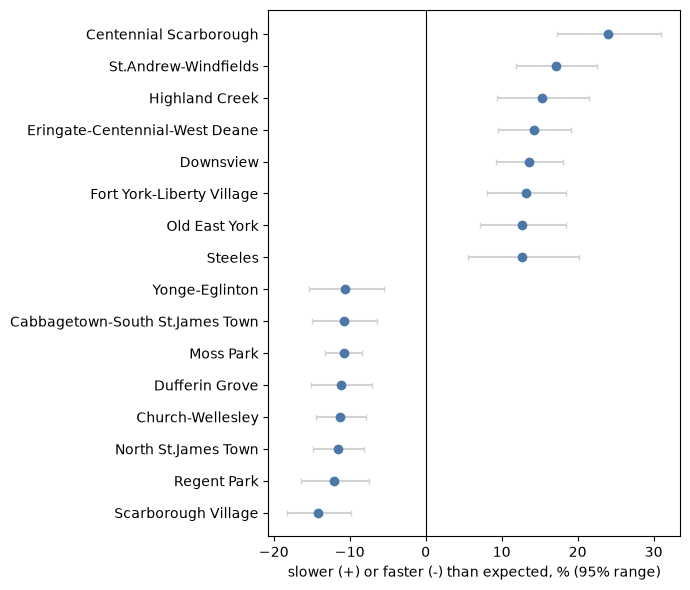

In [19]:
import matplotlib.pyplot as plt

top = g.sort_values("adj_shrunk_pct", ascending=False)
sel = pd.concat([top.head(8), top.tail(8)]).iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 6))
ax.errorbar(sel["adj_shrunk_pct"], range(len(sel)),
            xerr=[sel["adj_shrunk_pct"] - sel["lo_pct"], sel["hi_pct"] - sel["adj_shrunk_pct"]],
            fmt="o", color="#4C78A8", ecolor="lightgrey", capsize=2)
ax.set_yticks(range(len(sel)))
ax.set_yticklabels(sel["neighbourhood_name"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("slower (+) or faster (-) than expected, % (95% range)")
plt.tight_layout()
plt.show()

In [20]:
nb_level = d.groupby("neighbourhood_id").agg(median_s=("wait_s", "median"),
                                             mean_dist_km=("dist_nearest_km", "mean")).reset_index()
m = g.merge(nb_level, on="neighbourhood_id").merge(ctx.drop(columns="neighbourhood_name"), on="neighbourhood_id")

top_raw = set(m.nlargest(10, "median_s")["neighbourhood_id"])
top_adj = set(m.nlargest(10, "adj_shrunk_pct")["neighbourhood_id"])
print("neighbourhoods in BOTH top-10 lists (raw median vs adjusted):", len(top_raw & top_adj))

cols2 = ["mean_dist_km", "median_income", "pct_65_plus", "pct_renters", "pct_apt_5plus", "pct_built_before_1980"]
m[["adj_shrunk_pct"] + cols2].corr(method="spearman").round(2)["adj_shrunk_pct"]

neighbourhoods in BOTH top-10 lists (raw median vs adjusted): 1


adj_shrunk_pct           1.00
mean_dist_km             0.33
median_income            0.13
pct_65_plus              0.27
pct_renters             -0.35
pct_apt_5plus           -0.08
pct_built_before_1980   -0.24
Name: adj_shrunk_pct, dtype: float64

In [21]:
risk_vars = ["pct_built_before_1980", "pct_apt_5plus"]
for v in risk_vars:
    m[v + "_z"] = (m[v] - m[v].mean()) / m[v].std()
m["risk_score"] = m[[v + "_z" for v in risk_vars]].mean(axis=1)

m["clear_slow"] = m["lo_pct"] > 0
m["top_risk"] = m["risk_score"] >= m["risk_score"].quantile(0.75)

print(pd.crosstab(m["clear_slow"], m["top_risk"]))
m[m["clear_slow"] & m["top_risk"]].sort_values("adj_shrunk_pct", ascending=False)[
    ["neighbourhood_name", "n", "adj_shrunk_pct", "lo_pct", "pct_built_before_1980", "pct_apt_5plus"]].round(1)

top_risk    False  True 
clear_slow              
False          93     35
True           25      5


,neighbourhood_name,n,adj_shrunk_pct,lo_pct,pct_built_before_1980,pct_apt_5plus
104,Flemingdon Park,144,11.7,6.5,66.6,83.1
50,Fenside-Parkwoods,150,11.2,6.1,75.4,62.8
48,Parkwoods-O'Connor Hills,111,9.1,3.4,87.8,32.7
106,Don Valley Village,169,7.7,3.0,71.5,58.2
78,Mount Olive-Silverstone-Jamestown,236,4.1,0.2,58.2,62.0


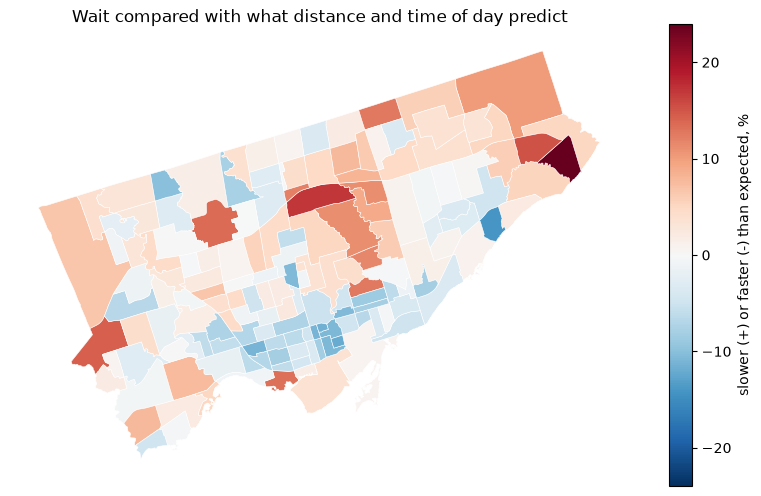

In [22]:
import json
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

nbhd = pd.read_csv("data/raw/Neighbourhoods - 4326.csv")
lookup = g.set_index("neighbourhood_id")["adj_shrunk_pct"]

def area(ring):
    x, y = np.array(ring).T
    return abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1))) / 2

items = []
for _, r in nbhd.iterrows():
    gm = json.loads(r["geometry"])
    polys = gm["coordinates"] if gm["type"] == "MultiPolygon" else [gm["coordinates"]]
    for poly in polys:
        items.append((area(poly[0]), np.array(poly[0]), lookup.get(str(r["AREA_SHORT_CODE"]), np.nan)))
items.sort(key=lambda t: -t[0])

lim = np.nanmax(np.abs([v for _, _, v in items]))
pc = PatchCollection([Polygon(p, closed=True) for _, p, _ in items],
                     cmap="RdBu_r", edgecolor="white", linewidth=0.4)
pc.set_array(np.array([v for _, _, v in items]))
pc.set_clim(-lim, lim)

fig, ax = plt.subplots(figsize=(10, 6))
ax.add_collection(pc)
ax.autoscale_view()
ax.set_aspect(1 / np.cos(np.radians(43.7)))
fig.colorbar(pc, label="slower (+) or faster (-) than expected, %")
ax.set_axis_off()
ax.set_title("Wait compared with what distance and time of day predict")
plt.show()

In [23]:
m.to_csv("data/processed/neighbourhood_adjusted_delay.csv", index=False)
print("saved", len(m), "neighbourhoods")

saved 158 neighbourhoods


# Stage 6b summary: which neighbourhoods are slower than expected?

The raw slowest neighbourhoods are mostly the ones farthest from a station, so I asked a sharper question: which neighbourhoods wait longer than their distance and time of day predict? I took each incident's residual (its actual log-wait minus the model's prediction) and averaged it per neighbourhood. Because a neighbourhood with few incidents can look extreme by luck, I shrank each estimate toward the city average by an amount that depends on how many incidents it has and how noisy they are. Differences between neighbourhoods are modest (a spread of about 7%) compared with the noise between individual incidents within one (about 32%), but every neighbourhood has at least 49 incidents, so the shrinking was gentle: the typical estimate kept about 87% of its size.

After this adjustment the ranking changes a lot. Only one neighbourhood appears in both the raw slowest ten and the adjusted slowest ten. The most delayed relative to expectation are Centennial Scarborough (about 24% slower than predicted, with a range of roughly 17% to 31%), St. Andrew-Windfields (17%), Highland Creek (15%), Eringate-Centennial-West Deane (14%) and Downsview (14%). The least delayed are Scarborough Village (14% faster than predicted), Regent Park, North St. James Town, Church-Wellesley and Dufferin Grove. Thirty neighbourhoods are clearly slower than expected and 35 are clearly faster, meaning their 95% range does not include zero.

To find where a closer look might matter most, I combined this with two crude fire-risk proxies, the share of homes built before 1980 and the share of apartments in buildings of five or more storeys. Five neighbourhoods are both clearly slower than expected and in the top quarter on that risk score: Flemingdon Park, Fenside-Parkwoods, Parkwoods-O'Connor Hills, Don Valley Village and Mount Olive-Silverstone-Jamestown. I treat that as a screening list, not a conclusion.

I need to be careful about what this means. "Slower than expected" is not the same as "underserved." Straight-line distance ignores ravines, highways, rail lines and street layout, which can make real trips much longer, and the wait also depends on dispatch, turnout and how times are recorded. The adjustment is incomplete too: adjusted delay still has a 0.33 rank correlation with average distance, so farther neighbourhoods tend to remain somewhat slower than the straight-line model predicts. The risk score is a rough proxy. So these results say where to look more closely, not that service differs for any particular reason.

## Some Important Points
**I shrinked small-sample estimates** because part of a small neighbourhood's average is luck, and shrinking stops chance from putting it at the top. It changed little here because every neighbourhood has plenty of incidents.  

**"Slower than expected" doesn't mean "underserved"** because the unexplained part can come from real road geography and unmeasured operational factors, and part of it is noise.